# 🦙 Tutoría 4 · Pipeline Completo
## Proyecto demostrativo: **El Comandero de Chida Café**

**Objetivo:** mostrar paso a paso cómo se conectan los conceptos del Módulo 1:

> **Mensaje → Clasificación → RAG → Prompt → Respuesta → Evaluación → App**

Esta versión está preparada para **explicarla en vivo**. No busca que el alumno memorice cada línea de código.

### Qué vamos a reforzar
- Clasificación: `pedido`, `pregunta`, `queja`, `otro`.
- Fine-tuning ligero con **LoRA**.
- Evaluación con **accuracy** y **matriz de confusión**.
- RAG con información propia del negocio.
- Prompt para controlar el tono.
- Enrutamiento de casos.
- Interfaz de prueba con **Gradio**.

> **Importante:** una app compartida desde Colab es un prototipo, no un despliegue productivo.

## 0. Mapa del pipeline

Antes de ejecutar código, explica la lógica:

1. Llega un mensaje.
2. El clasificador detecta la intención.
3. El sistema decide qué ruta seguir.
4. Si aplica, el RAG recupera información.
5. El prompt combina reglas + contexto.
6. El modelo genera una respuesta.
7. Evaluamos el clasificador.
8. Lo envolvemos en una interfaz.

**Pregunta al grupo:** ¿qué componente aporta conocimiento y cuál modifica comportamiento?

## 1. Preparar el entorno

- `transformers`: modelos y tokenizadores.
- `datasets`: datasets.
- `peft`: LoRA.
- `sentence-transformers`: embeddings.
- `scikit-learn`: métricas.
- `gradio`: interfaz.
- `groq`: llamada opcional a Llama por API.

In [11]:
!pip -q install transformers datasets peft accelerate sentence-transformers scikit-learn gradio groq

## 2. Importaciones y configuración

Todavía no entrenamos. Solo cargamos herramientas y comprobamos si hay GPU.

In [12]:
import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Instalamos las librerías necesarias para la práctica.
!pip -q install -U transformers datasets peft accelerate \
sentence-transformers scikit-learn gradio groq

# Colab incluye actualmente una versión antigua de torchao.
# Esta práctica no utiliza torchao, así que lo eliminamos
# para evitar conflictos con PEFT.
!pip uninstall -y torchao

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)
from peft import LoraConfig, TaskType, get_peft_model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU disponible: True
GPU: Tesla T4


## 3. Dataset del clasificador

Las cuatro categorías de esta práctica son:

- `pedido`
- `pregunta`
- `queja`
- `otro`

Usaremos **26 mensajes**: 18 para entrenamiento y 8 para prueba.

> En producción se necesitarían muchos más datos y una revisión cuidadosa de sesgos y cobertura.

In [13]:
train_data = [
    {"texto": "Quiero un capuchino por favor", "categoria": "pedido"},
    {"texto": "Me das un latte y un americano chico", "categoria": "pedido"},
    {"texto": "Voy a pedir dos cafés americanos", "categoria": "pedido"},
    {"texto": "Quisiera un capuchino con leche de avena", "categoria": "pedido"},
    {"texto": "Ponme un latte para llevar", "categoria": "pedido"},

    {"texto": "¿A qué hora cierran hoy?", "categoria": "pregunta"},
    {"texto": "¿Cuánto cuesta el capuchino?", "categoria": "pregunta"},
    {"texto": "¿Tienen leche de almendra?", "categoria": "pregunta"},
    {"texto": "¿Hay wifi para clientes?", "categoria": "pregunta"},
    {"texto": "¿A qué hora abren los domingos?", "categoria": "pregunta"},

    {"texto": "Mi café llegó frío y tardaron demasiado", "categoria": "queja"},
    {"texto": "El mesero me atendió muy mal", "categoria": "queja"},
    {"texto": "Me cobraron algo que no pedí", "categoria": "queja"},
    {"texto": "Esperé muchísimo por mi bebida", "categoria": "queja"},

    {"texto": "Hola, buen día", "categoria": "otro"},
    {"texto": "Qué bonito está el clima", "categoria": "otro"},
    {"texto": "¿Quién ganó el partido de ayer?", "categoria": "otro"},
    {"texto": "Cuéntame un chiste", "categoria": "otro"},
    {"texto": "dime hola", "categoria": "otro"}
]

test_data = [
    {"texto": "Dame un americano grande", "categoria": "pedido"},
    {"texto": "Quiero un capuchino con avena", "categoria": "pedido"},
    {"texto": "¿Cuál es el horario del domingo?", "categoria": "pregunta"},
    {"texto": "¿Cuánto vale un latte?", "categoria": "pregunta"},
    {"texto": "Encontré un problema con mi bebida y nadie me ayudó", "categoria": "queja"},
    {"texto": "El servicio fue muy lento y estoy molesto", "categoria": "queja"},
    {"texto": "Buenos días a todos", "categoria": "otro"},
    {"texto": "Recomiéndame una película", "categoria": "otro"},
]

df_train = pd.DataFrame(train_data)
df_test = pd.DataFrame(test_data)

print("Entrenamiento:", len(df_train))
print("Prueba:", len(df_test))
display(df_train.groupby("categoria").size().rename("ejemplos").to_frame())
display(df_train.head())

Entrenamiento: 19
Prueba: 8


,ejemplos
categoria,
otro,5
pedido,5
pregunta,5
queja,4


,texto,categoria
0,Quiero un capuchino por favor,pedido
1,Me das un latte y un americano chico,pedido
2,Voy a pedir dos cafés americanos,pedido
3,Quisiera un capuchino con leche de avena,pedido
4,Ponme un latte para llevar,pedido


### Pausa didáctica: “el dataset manda”

Antes de entrenar, pregunta:

- ¿Hay variedad de expresiones?
- ¿Las categorías están razonablemente representadas?
- ¿Los datos de prueba son distintos a los de entrenamiento?
- ¿Qué pasaría si una palabra aparece casi siempre en una sola clase?

## 4. Etiquetas numéricas

Los modelos trabajan con números, por eso convertimos:

`pedido → 0`, `pregunta → 1`, `queja → 2`, `otro → 3`.

In [14]:
labels = ["pedido", "pregunta", "queja", "otro"]
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

df_train["label"] = df_train["categoria"].map(label2id)
df_test["label"] = df_test["categoria"].map(label2id)

display(df_train[["texto", "categoria", "label"]].head(8))

,texto,categoria,label
0,Quiero un capuchino por favor,pedido,0
1,Me das un latte y un americano chico,pedido,0
2,Voy a pedir dos cafés americanos,pedido,0
3,Quisiera un capuchino con leche de avena,pedido,0
4,Ponme un latte para llevar,pedido,0
5,¿A qué hora cierran hoy?,pregunta,1
6,¿Cuánto cuesta el capuchino?,pregunta,1
7,¿Tienen leche de almendra?,pregunta,1


## 5. Cargar el modelo base

Usaremos `distilbert-base-multilingual-cased` para **clasificación**.

- Ya conoce patrones del lenguaje.
- No conoce todavía nuestras cuatro etiquetas.
- Después agregaremos LoRA para especializarlo.

> Clasificar no requiere obligatoriamente un LLM generativo.

In [15]:
MODELO_CLASIFICADOR = "distilbert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(MODELO_CLASIFICADOR)

modelo_base = AutoModelForSequenceClassification.from_pretrained(
    MODELO_CLASIFICADOR,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
)

print("Modelo cargado:", MODELO_CLASIFICADOR)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo cargado: distilbert-base-multilingual-cased


## 6. Tokenización

Flujo simplificado:

**Texto → tokenizer → tokens/IDs → modelo**

In [16]:
ds_train = Dataset.from_pandas(df_train[["texto", "label"]], preserve_index=False)
ds_test = Dataset.from_pandas(df_test[["texto", "label"]], preserve_index=False)

def tokenizar(batch):
    return tokenizer(batch["texto"], truncation=True, max_length=96)

ds_train_tok = ds_train.map(tokenizar, batched=True, remove_columns=["texto"])
ds_test_tok = ds_test.map(tokenizar, batched=True, remove_columns=["texto"])

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(ds_train_tok)

Map:   0%|          | 0/19 [00:00<?, ? examples/s]

Map:   0%|          | 0/8 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 19
})


## 7. Línea base: antes del ajuste

Medimos antes para poder comparar después.

> El porcentaje puede variar. La meta es entender el proceso, no obtener un número exacto.

In [17]:
def predecir_ids(modelo, dataset_tokenizado):
    modelo.eval()
    preds = []
    device = next(modelo.parameters()).device

    for ejemplo in dataset_tokenizado:
        entrada = {
            k: torch.tensor([v]).to(device)
            for k, v in ejemplo.items()
            if k in ["input_ids", "attention_mask"]
        }
        with torch.no_grad():
            logits = modelo(**entrada).logits
        preds.append(int(torch.argmax(logits, dim=-1).item()))
    return preds

device = "cuda" if torch.cuda.is_available() else "cpu"
modelo_base.to(device)

y_true = df_test["label"].tolist()
preds_antes = predecir_ids(modelo_base, ds_test_tok)
acc_antes = accuracy_score(y_true, preds_antes)

print(f"Accuracy ANTES: {acc_antes:.2%}")
print([id2label[p] for p in preds_antes])

Accuracy ANTES: 25.00%
['otro', 'otro', 'otro', 'otro', 'otro', 'otro', 'otro', 'otro']


## 8. Agregar LoRA

LoRA:
- mantiene congelada gran parte del modelo base;
- agrega adaptadores pequeños;
- entrena solo una fracción de parámetros.

In [18]:
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.10,
    target_modules=["q_lin", "v_lin"],
)

modelo_lora = get_peft_model(modelo_base, lora_config)
modelo_lora.print_trainable_parameters()

trainable params: 741,124 || all params: 136,068,872 || trainable%: 0.5447


## 9. Fine-tuning ligero

Para una demostración rápida usamos pocas épocas y pocos datos.

Si tienes poco tiempo de tutoría, reduce `NUM_EPOCHS`.

In [19]:
NUM_EPOCHS = 12

training_args = TrainingArguments(
    output_dir="./chida_clasificador_lora",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=4,
    learning_rate=5e-4,
    weight_decay=0.01,
    logging_steps=5,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=modelo_lora,
    args=training_args,
    train_dataset=ds_train_tok,
    data_collator=data_collator,
)

trainer.train()

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Step,Training Loss
5,1.416615
10,1.265469
15,1.143927
20,1.057177
25,0.919618
30,0.847586
35,0.738207
40,0.650228
45,0.573778
50,0.541428


TrainOutput(global_step=60, training_loss=0.844249979654948, metrics={'train_runtime': 3.9337, 'train_samples_per_second': 57.961, 'train_steps_per_second': 15.253, 'total_flos': 757699135440.0, 'train_loss': 0.844249979654948, 'epoch': 12.0})

## 10. Evaluar después

Repetimos la prueba con los mismos 8 mensajes.

In [20]:
pred_output = trainer.predict(ds_test_tok)
preds_despues = np.argmax(pred_output.predictions, axis=1)
acc_despues = accuracy_score(y_true, preds_despues)

comparacion = pd.DataFrame({
    "mensaje": df_test["texto"],
    "real": df_test["categoria"],
    "predicho": [id2label[int(p)] for p in preds_despues],
    "acierto": [
        real == id2label[int(p)]
        for real, p in zip(df_test["categoria"], preds_despues)
    ],
})

print(f"Accuracy ANTES:   {acc_antes:.2%}")
print(f"Accuracy DESPUÉS: {acc_despues:.2%}")
display(comparacion)

Accuracy ANTES:   25.00%
Accuracy DESPUÉS: 75.00%


,mensaje,real,predicho,acierto
0,Dame un americano grande,pedido,pedido,True
1,Quiero un capuchino con avena,pedido,pedido,True
2,¿Cuál es el horario del domingo?,pregunta,pregunta,True
3,¿Cuánto vale un latte?,pregunta,pregunta,True
4,Encontré un problema con mi bebida y nadie me ...,queja,queja,True
5,El servicio fue muy lento y estoy molesto,queja,queja,True
6,Buenos días a todos,otro,pedido,False
7,Recomiéndame una película,otro,pedido,False


## 11. Matriz de confusión

- Filas: clase real.
- Columnas: predicción.
- Diagonal: aciertos.
- Fuera de la diagonal: errores.

**Idea clave:** una queja clasificada como `otro` puede ser más costosa que confundir un saludo.

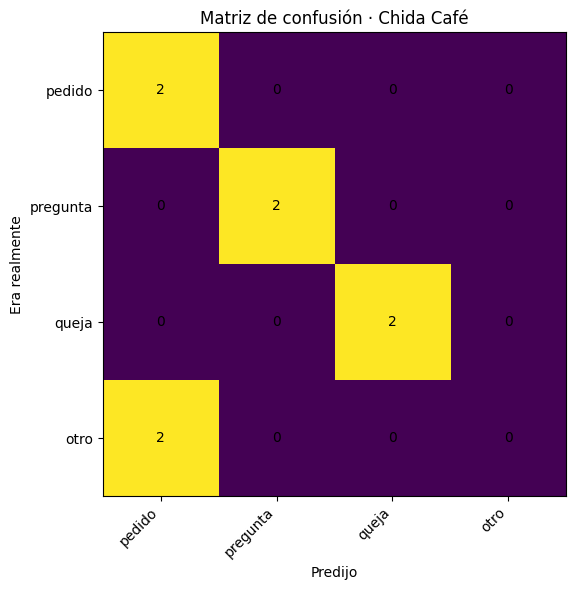

              precision    recall  f1-score   support

      pedido       0.50      1.00      0.67         2
    pregunta       1.00      1.00      1.00         2
       queja       1.00      1.00      1.00         2
        otro       0.00      0.00      0.00         2

    accuracy                           0.75         8
   macro avg       0.62      0.75      0.67         8
weighted avg       0.62      0.75      0.67         8



In [21]:
cm = confusion_matrix(y_true, preds_despues, labels=list(range(len(labels))))

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm)
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_xlabel("Predijo")
ax.set_ylabel("Era realmente")
ax.set_title("Matriz de confusión · Chida Café")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    preds_despues,
    target_names=labels,
    zero_division=0
))

## 12. Función de clasificación

Ya tenemos una pieza reutilizable:

**Mensaje → Clasificador → Etiqueta**

In [22]:
def clasificar_mensaje(texto):
    modelo_lora.eval()
    device = next(modelo_lora.parameters()).device

    entrada = tokenizer(
        texto,
        return_tensors="pt",
        truncation=True,
        max_length=96,
    ).to(device)

    with torch.no_grad():
        logits = modelo_lora(**entrada).logits

    pred_id = int(torch.argmax(logits, dim=-1).item())
    return id2label[pred_id]

for mensaje in [
    "Quiero un capuchino",
    "¿A qué hora abren?",
    "Me atendieron muy mal",
    "Dime quién ganó el mundial",
]:
    print(f"{mensaje!r} -> {clasificar_mensaje(mensaje)}")

'Quiero un capuchino' -> pedido
'¿A qué hora abren?' -> pregunta
'Me atendieron muy mal' -> queja
'Dime quién ganó el mundial' -> pedido


# BLOQUE 2 · RAG
## 13. Base de conocimiento

La información específica del negocio vive fuera del modelo.

Esta demo usa:
- horarios;
- precios;
- leches alternativas;
- wifi.

In [23]:
base_conocimiento = [
    {
        "seccion": "HORARIOS",
        "contenido": (
            "Lunes a viernes 7:00–21:00. "
            "Sábados 8:00–22:00. "
            "Domingos 9:00–18:00."
        ),
    },
    {
        "seccion": "CAFÉ CALIENTE",
        "contenido": (
            "Americano $38 chico, $45 grande. "
            "Capuchino $52. Latte $55."
        ),
    },
    {
        "seccion": "LECHES ALTERNATIVAS",
        "contenido": (
            "Cambio a almendra, avena o soya: +$12 en cualquier bebida."
        ),
    },
    {
        "seccion": "WIFI",
        "contenido": (
            "Sí hay wifi gratis. "
            "Red: ChidaCafe_Clientes. "
            "Contraseña: cafecito2026."
        ),
    },
]

df_kb = pd.DataFrame(base_conocimiento)
display(df_kb)

,seccion,contenido
0,HORARIOS,Lunes a viernes 7:00–21:00. Sábados 8:00–22:00...
1,CAFÉ CALIENTE,"Americano $38 chico, $45 grande. Capuchino $52..."
2,LECHES ALTERNATIVAS,"Cambio a almendra, avena o soya: +$12 en cualq..."
3,WIFI,Sí hay wifi gratis. Red: ChidaCafe_Clientes. C...


## 14. Embeddings

Los embeddings permiten buscar por **significado**, no solo por coincidencia exacta.

In [24]:
MODELO_EMBEDDINGS = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

modelo_embeddings = SentenceTransformer(MODELO_EMBEDDINGS)

textos_kb = [
    f"{fila['seccion']}: {fila['contenido']}"
    for _, fila in df_kb.iterrows()
]

emb_kb = modelo_embeddings.encode(textos_kb, normalize_embeddings=True)

print("Secciones indexadas:", len(textos_kb))
print("Dimensión:", emb_kb.shape[1])

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Secciones indexadas: 4
Dimensión: 384


## 15. Recuperar antes de responder

Si la similitud es baja, preferimos **no inventar**.

In [25]:
UMBRAL = 0.45

def recuperar_contexto(pregunta, umbral=UMBRAL):
    emb_pregunta = modelo_embeddings.encode([pregunta], normalize_embeddings=True)
    similitudes = cosine_similarity(emb_pregunta, emb_kb)[0]

    idx = int(np.argmax(similitudes))
    score = float(similitudes[idx])

    if score < umbral:
        return None, score

    return base_conocimiento[idx], score

for q in [
    "¿A qué hora abren los domingos?",
    "¿Cuánto cuesta un capuchino?",
    "¿Tienen algo sin lactosa?",
    "¿Tienen wifi?",
    "¿Venden malteada de fresa?",
]:
    contexto, score = recuperar_contexto(q)
    print("\nPregunta:", q)
    print("Similitud:", round(score, 3))
    print("Contexto:", contexto)


Pregunta: ¿A qué hora abren los domingos?
Similitud: 0.731
Contexto: {'seccion': 'HORARIOS', 'contenido': 'Lunes a viernes 7:00–21:00. Sábados 8:00–22:00. Domingos 9:00–18:00.'}

Pregunta: ¿Cuánto cuesta un capuchino?
Similitud: 0.59
Contexto: {'seccion': 'CAFÉ CALIENTE', 'contenido': 'Americano $38 chico, $45 grande. Capuchino $52. Latte $55.'}

Pregunta: ¿Tienen algo sin lactosa?
Similitud: 0.4
Contexto: None

Pregunta: ¿Tienen wifi?
Similitud: 0.587
Contexto: {'seccion': 'WIFI', 'contenido': 'Sí hay wifi gratis. Red: ChidaCafe_Clientes. Contraseña: cafecito2026.'}

Pregunta: ¿Venden malteada de fresa?
Similitud: 0.394
Contexto: None


# BLOQUE 3 · PROMPT
## 16. Voz del mesero

El RAG aporta el dato.  
El prompt decide cómo expresarlo.

Reglas:
- amable y relajado;
- trato de “tú”;
- español mexicano;
- 1 a 3 frases;
- uno o dos emojis;
- solo usar datos recuperados;
- si no existe el dato, no inventarlo.

In [26]:
REGLAS_MESERO = """
Eres el asistente de Chida Café.

Reglas de estilo:
- Habla como un mesero amable y relajado.
- Trata al cliente de tú.
- Responde en español mexicano.
- Usa de 1 a 3 frases.
- Puedes usar uno o dos emojis.
- Usa únicamente los DATOS DEL NEGOCIO proporcionados.
- Si el dato solicitado no aparece en el contexto, dilo claramente y ofrece que alguien del equipo lo confirme.
""".strip()

print(REGLAS_MESERO)

Eres el asistente de Chida Café.

Reglas de estilo:
- Habla como un mesero amable y relajado.
- Trata al cliente de tú.
- Responde en español mexicano.
- Usa de 1 a 3 frases.
- Puedes usar uno o dos emojis.
- Usa únicamente los DATOS DEL NEGOCIO proporcionados.
- Si el dato solicitado no aparece en el contexto, dilo claramente y ofrece que alguien del equipo lo confirme.


## 17. Groq/Llama opcional

Busca una API key en Colab Secrets con nombre:

`GROQ_API_KEY`

Si no existe, el pipeline sigue funcionando con un fallback.

In [27]:
client_groq = None
GROQ_MODEL = None

try:
    from google.colab import userdata
    from groq import Groq

    api_key = userdata.get("GROQ_API_KEY")
    client_groq = Groq(api_key=api_key)

    modelos = client_groq.models.list()
    ids = [m.id for m in modelos.data]
    preferidos = [m for m in ids if "llama" in m.lower()]

    if preferidos:
        GROQ_MODEL = preferidos[0]
        print("Groq configurado.")
        print("Modelo Llama seleccionado:", GROQ_MODEL)
    else:
        print("No encontré un modelo Llama disponible en esta cuenta.")
        client_groq = None

except Exception as e:
    print("Groq no quedó configurado. Usaremos fallback.")
    print(type(e).__name__, "-", str(e)[:180])

Groq configurado.
Modelo Llama seleccionado: meta-llama/llama-prompt-guard-2-22m


## 18. Generar la respuesta

Conectamos:

**pregunta + contexto + reglas → respuesta**

In [28]:
def responder_con_contexto(pregunta, contexto):
    if contexto is None:
        return (
            "Uy, ese dato no lo tengo a la mano. "
            "Con gusto alguien del equipo te lo puede confirmar 😊"
        )

    contexto_txt = f"{contexto['seccion']}: {contexto['contenido']}"

    if client_groq is not None and GROQ_MODEL is not None:
        prompt = (
            REGLAS_MESERO
            + "\n\nDATOS DEL NEGOCIO:\n"
            + contexto_txt
            + "\n\nMENSAJE DEL CLIENTE:\n"
            + pregunta
            + "\n\nRESPUESTA:"
        )

        try:
            respuesta = client_groq.chat.completions.create(
                model=GROQ_MODEL,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.2,
                max_tokens=120,
            )
            return respuesta.choices[0].message.content.strip()
        except Exception as e:
            print("Groq falló; usaré fallback:", type(e).__name__)

    return f"Claro 😊 Según nuestra información: {contexto['contenido']}"

# BLOQUE 4 · ORQUESTAR
## 19. Función principal del Comandero

Rutas:
- `queja` → humano.
- `otro` → fuera de alcance.
- `pregunta` / `pedido` → RAG + respuesta.

In [29]:
def atender_mensaje(mensaje):
    categoria = clasificar_mensaje(mensaje)

    if categoria == "queja":
        return (
            f"🏷️ Clasificación: {categoria.upper()}\n\n"
            "Lamento mucho lo que nos cuentas. "
            "Voy a pasar tu caso a una persona del equipo para que pueda revisarlo contigo."
        )

    if categoria == "otro":
        return (
            f"🏷️ Clasificación: {categoria.upper()}\n\n"
            "Puedo ayudarte con pedidos, horarios, precios y servicios de Chida Café ☕"
        )

    contexto, score = recuperar_contexto(mensaje)
    respuesta = responder_con_contexto(mensaje, contexto)
    seccion = contexto["seccion"] if contexto else "SIN RESULTADO"

    return (
        f"🏷️ Clasificación: {categoria.upper()}\n"
        f"📚 RAG: {seccion} · similitud {score:.3f}\n\n"
        f"{respuesta}"
    )

for m in [
    "¿A qué hora abren los domingos?",
    "Quiero un capuchino",
    "El mesero me trató muy mal",
    "¿Venden malteada de fresa?",
]:
    print("=" * 80)
    print("CLIENTE:", m)
    print(atender_mensaje(m))

CLIENTE: ¿A qué hora abren los domingos?
🏷️ Clasificación: PREGUNTA
📚 RAG: HORARIOS · similitud 0.731

0.010524069890379906
CLIENTE: Quiero un capuchino
🏷️ Clasificación: PEDIDO
📚 RAG: SIN RESULTADO · similitud 0.277

Uy, ese dato no lo tengo a la mano. Con gusto alguien del equipo te lo puede confirmar 😊
CLIENTE: El mesero me trató muy mal
🏷️ Clasificación: QUEJA

Lamento mucho lo que nos cuentas. Voy a pasar tu caso a una persona del equipo para que pueda revisarlo contigo.
CLIENTE: ¿Venden malteada de fresa?
🏷️ Clasificación: PREGUNTA
📚 RAG: SIN RESULTADO · similitud 0.394

Uy, ese dato no lo tengo a la mano. Con gusto alguien del equipo te lo puede confirmar 😊


## 20. Leer el pipeline como ingenieros

Para cada mensaje pregunta:

1. ¿Qué categoría asignó?
2. ¿Qué ruta tomó?
3. ¿Consultó el RAG?
4. ¿Qué contexto recuperó?
5. ¿La respuesta usa ese dato?
6. ¿Qué parte conviene escalar a un humano?

Prueba especialmente una pregunta sobre algo que **no exista** en la base de conocimiento.

## 21. Interfaz con Gradio

Gradio sirve para probar el prototipo mediante un enlace.

**No equivale a producción**: no incorpora por sí solo autenticación, monitoreo, disponibilidad permanente ni un endpoint productivo.

In [30]:
import gradio as gr

demo = gr.Interface(
    fn=atender_mensaje,
    inputs=gr.Textbox(
        lines=3,
        label="Mensaje del cliente",
        placeholder="Ejemplo: ¿Cuánto cuesta un capuchino?",
    ),
    outputs=gr.Textbox(lines=8, label="Respuesta del Comandero"),
    title="☕ El Comandero · Chida Café",
    description=(
        "Demo educativa: clasificación + RAG + respuesta. "
        "No es un sistema de producción."
    ),
    examples=[
        ["¿A qué hora abren los domingos?"],
        ["Quiero un capuchino"],
        ["El servicio fue muy lento y estoy molesto"],
        ["¿Venden malteada de fresa?"],
    ],
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2639bc390638fd5390.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# 22. Cierre

## Pipeline construido

**Cliente → Clasificador LoRA → Enrutamiento → RAG → Prompt → Llama/generador → Respuesta → Gradio**

### ¿Qué le falta para producción?
- endpoint/API estable;
- servidor/despliegue;
- autenticación y seguridad;
- manejo de errores y timeouts;
- pruebas end-to-end;
- monitoreo;
- documentación;
- dataset y evaluación más robustos.

> **Idea final:** que funcione en Colab demuestra un prototipo; producción exige que el sistema completo sea estable, consumible, medible y mantenible.

# 23. Preguntas de cierre

1. ¿Qué diferencia hay entre lo que aprendió LoRA y lo que contiene el RAG?
2. ¿Qué significa una celda fuera de la diagonal?
3. ¿Por qué no reentrenaríamos el modelo solo para cambiar un precio?
4. ¿Por qué una queja sigue una ruta distinta?
5. ¿Qué diferencia hay entre esta app de Gradio y un servicio en producción?